# Customer Churn & CLV — Business Impact

## Objective

The model tells us **who** is likely to leave. But the business question is different:

> **With a limited budget, which customers should the retention campaign target to protect the most revenue?**

In this notebook I combine the churn probability with the value of each customer and simulate a retention campaign on the test period (September → December 2011).

In [1]:
# Import all the libraries necessary for this section
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the test set with the churn probabilities
test_scored = pd.read_csv("../data/processed/test_scored.csv")

# Folder to save the images used in the README
Path("../images").mkdir(exist_ok=True)

test_scored.head()

,CustomerID,recency_days,frequency,monetary,churn,churn_probability
0,12347,37,3,1603.68,0,0.226468
1,12348,156,1,327.00,0,0.576627
2,12352,170,2,240.66,0,0.612247
3,12353,112,1,89.00,1,0.701332
4,12354,140,1,1079.40,1,0.490243


## 1. Customer value (CLV) and expected loss

- **CLV (Customer Lifetime Value):** the value a customer generates for the company. I use a simple proxy: the revenue of the last 180 days, annualised. A more advanced option would be a BG/NBD + Gamma-Gamma model.
- **Expected loss = churn probability × CLV.** For example, a customer worth £10,000 per year with 30% risk has an expected loss of £3,000, while a customer worth £200 with 70% risk has an expected loss of £140.

In [3]:
# Calculate the CLV proxy (annualised revenue of the last 180 days)
test_scored["clv"] = test_scored["monetary"] * 365 / 180

# Calculate the expected loss
test_scored["expected_loss"] = test_scored["churn_probability"] * test_scored["clv"]

test_scored[["CustomerID", "churn_probability", "clv", "expected_loss"]].sort_values("expected_loss", ascending=False).head(10)

,CustomerID,churn_probability,clv,expected_loss
1323,15098,0.497652,80941.791667,40280.819362
1618,15749,0.624354,43670.019444,27265.541916
1110,14646,0.067194,243391.327778,16354.551312
2684,18102,0.070382,194027.227222,13655.929887
35,12415,0.083543,129565.145000,10824.283858
1237,14911,0.081795,124161.563333,10155.833059
122,12590,0.504125,18941.999444,9549.137947
841,14088,0.250805,36424.931667,9135.543565
290,12931,0.144573,62166.191667,8987.544587
871,14156,0.067936,129470.305833,8795.758953


## 2. Comparing targeting strategies

The campaign can contact **20% of the active customers** (555 customers). I compare four ways of choosing them. Since this is the test period, I know which customers really churned, so I can measure the share of the **lost value** that each strategy reaches.

In [4]:
# Define the strategies (the column used to rank the customers)
strategies = {
    "Random": None,
    "Highest churn probability": "churn_probability",
    "Highest value (CLV)": "clv",
    "Highest expected loss": "expected_loss",
}

contacts = int(len(test_scored) * 0.20)
lost_value = test_scored.loc[test_scored["churn"] == 1, "clv"].sum()

print(f"Customers contacted: {contacts}")
print(f"Total value of the customers who churned: £{lost_value:,.0f}")

Customers contacted: 555
Total value of the customers who churned: £1,252,549


In [5]:
# Evaluate each strategy
results = []

for name, column in strategies.items():

    if column is None:
        selected = test_scored.sample(contacts, random_state=42)
    else:
        selected = test_scored.nlargest(contacts, column)

    churners = selected[selected["churn"] == 1]

    results.append({
        "strategy": name,
        "churners_reached": len(churners),
        "precision": len(churners) / contacts,
        "lost_value_reached": churners["clv"].sum(),
        "share_of_lost_value": churners["clv"].sum() / lost_value,
    })

strategy_results = pd.DataFrame(results)
strategy_results

,strategy,churners_reached,precision,lost_value_reached,share_of_lost_value
0,Random,200,0.360360,213441.739444,0.170406
1,Highest churn probability,338,0.609009,157444.676389,0.125699
2,Highest value (CLV),75,0.135135,481839.440278,0.384687
3,Highest expected loss,137,0.246847,587347.678611,0.468922


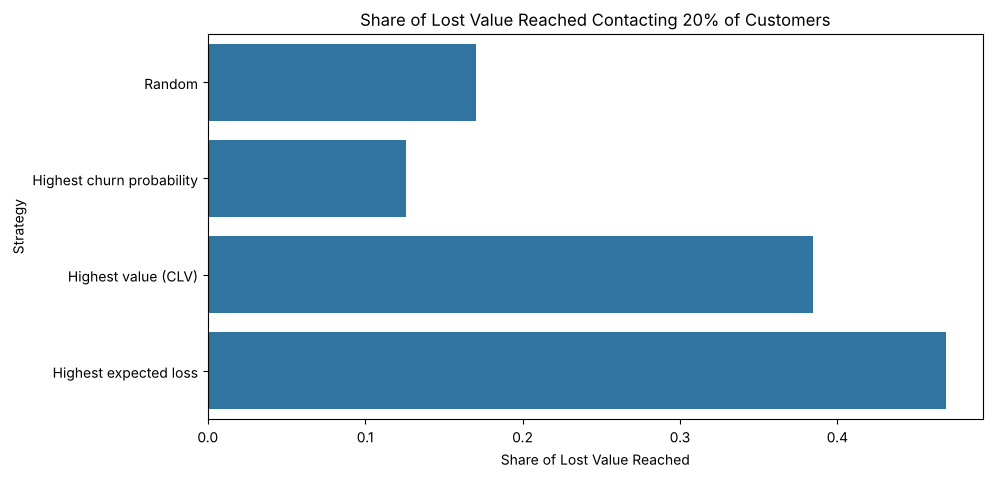

In [6]:
# Plot the share of lost value reached by each strategy
plt.figure(figsize=(10, 5))

sns.barplot(data=strategy_results, x="share_of_lost_value", y="strategy")

plt.title("Share of Lost Value Reached Contacting 20% of Customers")
plt.xlabel("Share of Lost Value Reached")
plt.ylabel("Strategy")
plt.savefig("../images/strategy_comparison.png", bbox_inches="tight", dpi=150)
plt.show()

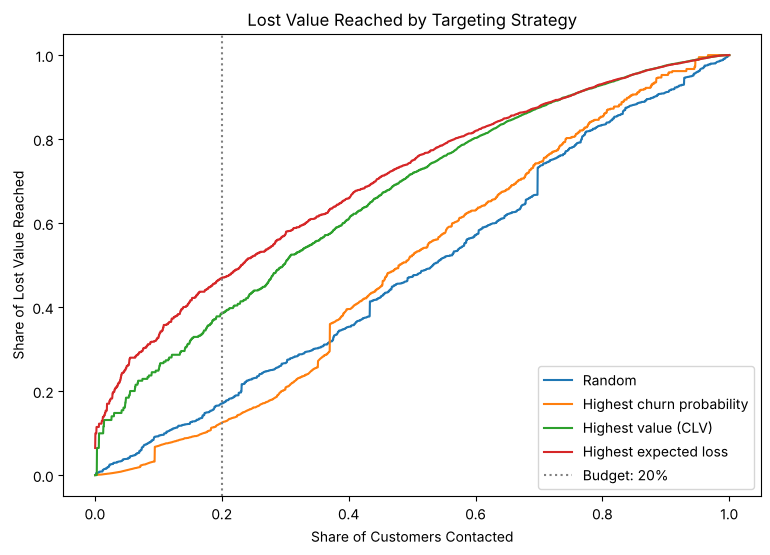

In [7]:
# Plot how much lost value each strategy reaches depending on the number of customers contacted
plt.figure(figsize=(9, 6))

for name, column in strategies.items():

    if column is None:
        ordered = test_scored.sample(frac=1, random_state=42)
    else:
        ordered = test_scored.sort_values(column, ascending=False)

    value_reached = np.cumsum(np.where(ordered["churn"] == 1, ordered["clv"], 0)) / lost_value
    customers_contacted = np.arange(1, len(ordered) + 1) / len(ordered)

    plt.plot(customers_contacted, value_reached, label=name)

plt.axvline(0.20, color="grey", linestyle=":", label="Budget: 20%")
plt.title("Lost Value Reached by Targeting Strategy")
plt.xlabel("Share of Customers Contacted")
plt.ylabel("Share of Lost Value Reached")
plt.legend()
plt.savefig("../images/value_curve.png", bbox_inches="tight", dpi=150)
plt.show()

### Key Findings

This is the most important result of the project:

- Ranking by **churn probability** finds the most churners (61% precision), but most of them are small customers. It reaches **only 13% of the lost value, even less than random (17%)**.
- Ranking by **value** works better (39%), but it spends contacts on big customers who were not going to leave.
- Ranking by **expected loss** reaches **47% of the lost value contacting only 20% of the customers**, almost 4 times more than the probability ranking.

The best churn model is not the one with the highest AUC, but the one that is combined with the value of the customer to take the decision.

## 3. Campaign simulation

To translate this into money I need some assumptions. In a real project they would come from the client (and ideally from an A/B test), so I keep them as parameters:

In [8]:
# Campaign assumptions
COST_PER_CONTACT = 15   # £ per customer contacted (call + voucher)
SAVE_RATE = 0.20        # share of the contacted churners that the campaign retains
MARGIN = 0.30           # gross margin on the retained revenue


def net_benefit(column, share_contacted, save_rate=SAVE_RATE):
    n_contacts = int(len(test_scored) * share_contacted)
    selected = test_scored.nlargest(n_contacts, column)
    saved_profit = save_rate * MARGIN * selected.loc[selected["churn"] == 1, "clv"].sum()
    return saved_profit - COST_PER_CONTACT * n_contacts

In [9]:
# Calculate the net benefit of each strategy for different save rates (contacting 20%)
sensitivity = pd.DataFrame({
    f"save rate {rate:.0%}": {name: net_benefit(column, 0.20, rate) for name, column in strategies.items() if column}
    for rate in [0.10, 0.20, 0.30]
}).round(0)

sensitivity

,save rate 10%,save rate 20%,save rate 30%
Highest churn probability,-3602.0,1122.0,5845.0
Highest value (CLV),6130.0,20585.0,35041.0
Highest expected loss,9295.0,26916.0,44536.0


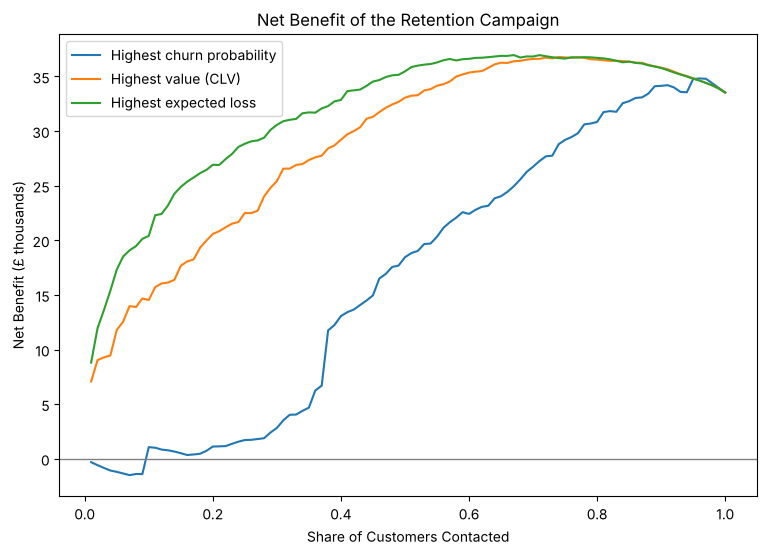

In [10]:
# Plot the net benefit depending on the share of customers contacted
shares = np.linspace(0.01, 1, 100)

plt.figure(figsize=(9, 6))

for name, column in strategies.items():
    if column:
        plt.plot(shares, [net_benefit(column, s) / 1000 for s in shares], label=name)

plt.axhline(0, color="grey", linewidth=1)
plt.title("Net Benefit of the Retention Campaign")
plt.xlabel("Share of Customers Contacted")
plt.ylabel("Net Benefit (£ thousands)")
plt.legend()
plt.show()

In [11]:
# Compare the benefit of contacting 20% with the maximum possible benefit
benefit_20 = net_benefit("expected_loss", 0.20)
best_share = shares[np.argmax([net_benefit("expected_loss", s) for s in shares])]
benefit_max = net_benefit("expected_loss", best_share)

print(f"Net benefit contacting 20%: £{benefit_20:,.0f}")
print(f"Maximum net benefit: £{benefit_max:,.0f} (contacting {best_share:.0%} of the customers)")
print(f"Contacting 20% already gives {benefit_20 / benefit_max:.0%} of the maximum")

Net benefit contacting 20%: £26,916
Maximum net benefit: £36,956 (contacting 67% of the customers)
Contacting 20% already gives 73% of the maximum


### Key Findings

- With my assumptions, contacting 20% of the customers ranked by expected loss gives a **net benefit of about £26,900**, compared with only **£1,100** ranking by churn probability.
- The expected loss ranking is the best option **for every save rate**. The amounts change with the assumptions, but the order of the strategies doesn't.
- There are **diminishing returns**: the first 20% of contacts already give 73% of the maximum benefit.

## 4. Customer segmentation and Next Best Action

To make the results useful for the marketing team, I place every customer in a **risk × value matrix** and assign one action to each segment:

- **High risk:** churn probability above the average predicted probability.
- **High value:** top 25% of CLV.

In [12]:
# Define the thresholds
risk_threshold = test_scored["churn_probability"].mean()
value_threshold = test_scored["clv"].quantile(0.75)

high_risk = test_scored["churn_probability"] >= risk_threshold
high_value = test_scored["clv"] >= value_threshold

print(f"Risk threshold: {risk_threshold:.1%}")
print(f"Value threshold: £{value_threshold:,.0f} per year")

Risk threshold: 40.4%
Value threshold: £2,251 per year


In [13]:
# Assign each customer to a segment
test_scored["segment"] = np.select(
    [high_value & high_risk, high_value & ~high_risk, ~high_value & high_risk],
    ["1. Save now", "2. Protect & grow", "3. Automated win-back"],
    default="4. Business as usual"
)

# Recommended action for each segment
actions = {
    "1. Save now": "Account manager call + tailored offer within 2 weeks",
    "2. Protect & grow": "Loyalty programme, early access to the Q4 catalogue, cross-selling",
    "3. Automated win-back": "Automated email sequence with a time-limited discount",
    "4. Business as usual": "Standard newsletter, no incentive spend",
}
test_scored["action"] = test_scored["segment"].map(actions)

test_scored["segment"].value_counts().sort_index()

segment
1. Save now                64
2. Protect & grow         630
3. Automated win-back    1409
4. Business as usual      672
Name: count, dtype: int64

In [14]:
# Create a summary table of each segment
segment_summary = (
    test_scored
    .groupby("segment")
    .agg(
        customers=("CustomerID", "count"),
        avg_churn_probability=("churn_probability", "mean"),
        real_churn_rate=("churn", "mean"),
        avg_clv=("clv", "mean"),
    )
)

lost_by_segment = test_scored[test_scored["churn"] == 1].groupby("segment")["clv"].sum()
segment_summary["share_of_lost_value"] = lost_by_segment / lost_value
segment_summary["action"] = segment_summary.index.map(actions)

segment_summary.round(2)

,customers,avg_churn_probability,real_churn_rate,avg_clv,share_of_lost_value,action
segment,,,,,,
1. Save now,64,0.48,0.48,6134.81,0.20,Account manager call + tailored offer within 2...
2. Protect & grow,630,0.18,0.11,8002.09,0.24,"Loyalty programme, early access to the Q4 cata..."
3. Automated win-back,1409,0.55,0.54,624.73,0.36,Automated email sequence with a time-limited d...
4. Business as usual,672,0.30,0.31,1346.36,0.21,"Standard newsletter, no incentive spend"


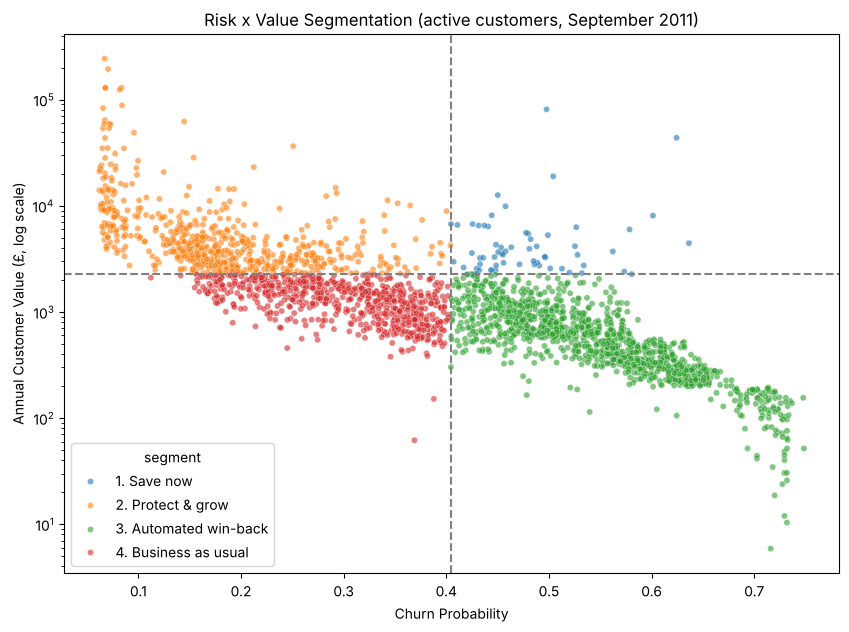

In [15]:
# Plot the risk x value matrix
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=test_scored.sort_values("segment"),
    x="churn_probability",
    y="clv",
    hue="segment",
    alpha=0.6,
    s=20
)

plt.axvline(risk_threshold, color="grey", linestyle="--")
plt.axhline(value_threshold, color="grey", linestyle="--")
plt.yscale("log")

plt.title("Risk x Value Segmentation (active customers, September 2011)")
plt.xlabel("Churn Probability")
plt.ylabel("Annual Customer Value (£, log scale)")
plt.savefig("../images/risk_value_matrix.png", bbox_inches="tight", dpi=150)
plt.show()

### Key Findings

- **Save now:** only **64 customers (about 2% of the base)** concentrate **20% of the value lost** in the test period. This is where a personal call from an account manager is worth the cost.
- **Protect & grow:** high-value customers with low risk. They should not receive discounts, but loyalty actions to keep them close.
- **Automated win-back:** the biggest group (1,409 customers), with high risk but low value. A cheap automated email campaign is the right action.
- **Business as usual:** no special spend.

In [16]:
# Save the scored customers for the Streamlit application
APP_DATA_PATH = Path("../app_data/customers_scored.csv")
APP_DATA_PATH.parent.mkdir(exist_ok=True)

test_scored.to_csv(APP_DATA_PATH, index=False)

print(f"Scored customers saved to: {APP_DATA_PATH}")

Scored customers saved to: ../app_data/customers_scored.csv


## Conclusions

### Recommendations for the business

1. **Target customers by expected revenue at risk, not by churn probability.** With the same budget it reaches 47% of the lost value instead of 13%.
2. **Start with the 64 "Save now" customers**, where personal contact pays off.
3. **Use cheap automated campaigns** for low-value customers at risk, and don't spend incentives on customers who are not at risk.
4. **Launch the campaign in September**, before the Q4 peak.

### Limitations

- **Prediction is not causality.** The model finds customers who are likely to leave, not the customers whose behaviour the campaign would change. The next step would be an **A/B test** and an **uplift model**.
- The **CLV is a simple proxy**. A BG/NBD + Gamma-Gamma model would give a better estimate of future value.
- The campaign assumptions (cost, save rate, margin) are mine and should be validated with the business.